In [1]:
import random, time, signal
import matplotlib.pyplot as plt

import threading
import _thread

import numpy as np

In [2]:
## Two protein sequences x and y of lengths n and m over the 20-letter amino-acid alphabet, 
## and an integer k. Decide whether x and y share a substring of length exactly k, and if so return one.

## 1.1. Implement the naive algorithm: for every position of x, compare the window of length k
## against every position of y. State and prove its worst-case bound in n, m and k.
def substring_shared(x, y, n, m, k):
    substring_length = 0
    for i in range(0, n - k + 1):
        for j in range(0, m - k + 1):
            substring_length = 0

            for window in range(k):
                if x[i + window] == y[j + window]:
                    substring_length += 1
                else:
                    break
            if substring_length == k:
                return 1

    return 0


In [3]:
## 1.2. Implement a hashing-based algorithm: store all k-mers of x in a set, then scan y. State
## and prove its expected bound. State what its worst-case bound is and when it occurs.

def find_kmer_hashing(x, y, n, m, k):

    if k == 0:
        return "Invalid k value, insert a k of at least two"
    if k > n or k > m:
        return None

    BASE = 131
    MOD = 10**9 + 7

    def val(c):
        return ord(c)

    def first_hash(s, start):
        h = 0
        for t in range(k):
            h = (h * BASE + val(s[start + t])) % MOD
        return h

    power = pow(BASE, k - 1, MOD)

    # Store hashes of all k-mers of x
    x_hashes = {}

    h = first_hash(x, 0)
    x_hashes.setdefault(h, []).append(0)

    for i in range(1, n - k + 1):
        h = (h - val(x[i - 1]) * power) % MOD
        h = (h * BASE + val(x[i + k - 1])) % MOD
        x_hashes.setdefault(h, []).append(i)

    # Scan y
    h = first_hash(y, 0)

    for j in range(m - k + 1):
        if j > 0:
            h = ((h - val(y[j - 1]) * power) * BASE + val(y[j + k - 1])) % MOD
        if h in x_hashes:
            for i in x_hashes[h]:
                if x[i:i + k] == y[j:j + k]:
                    return y[j:j + k]

    return None    


n=      10  k=  3  naive=2.3499946109950542e-05  hash=5.749997217208147e-05
n=      10  k= 10  naive=1.170008908957243e-05  hash=3.829994238913059e-05
n=     100  k=  3  naive=0.0017960999393835664  hash=0.0002234999556094408
n=     100  k= 10  naive=0.0015131999971345067  hash=0.00017929996829479933
n=     100  k= 50  naive=0.0004944000393152237  hash=8.999998681247234e-05
n=    1000  k=  3  naive=0.0017191000515595078  hash=0.0007217000238597393
n=    1000  k= 10  naive=0.19189040001947433  hash=0.0011720999609678984
n=    1000  k= 50  naive=0.17613839998375624  hash=0.0009822000283747911
n=   10000  k=  3  naive=0.00024670001585036516  hash=0.011136600049212575
n=   10000  k= 10  naive=None  hash=0.013949000043794513
n=   10000  k= 50  naive=None  hash=0.010329399956390262
n=  100000  k=  3  naive=1.3699987903237343e-05  hash=0.0782920999918133
n=  100000  k= 10  naive=None  hash=0.22116320009808987
n=  100000  k= 50  naive=None  hash=0.14870130002964288
n= 1000000  k=  3  naive=0.0

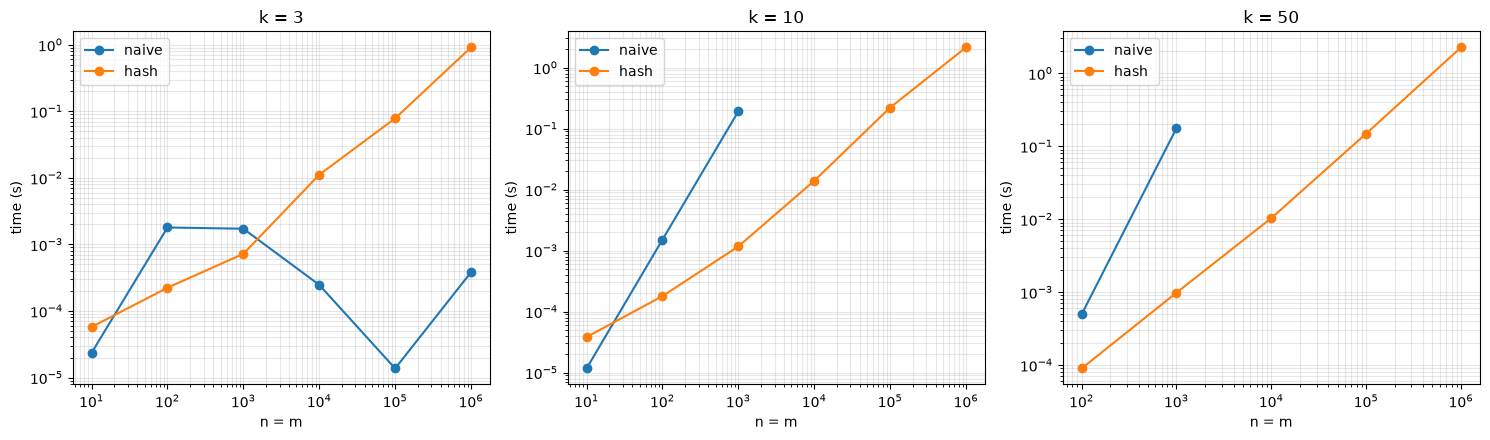

In [4]:
## 1.3. Benchmark both on random sequences with n = m ∈ {103, 104, 105, 106} 
## and k ∈ {3, 10, 50}.Plot running time against n for each k, and report 
## the crossover point at which the hash-ing algorithm becomes faster. 
## Explain why the naive algorithm wins below it, in terms of the constants that the asymptotic bound hides.


def time_call(f, args, limit=10):
    """Return elapsed seconds, or None if it exceeds `limit`."""
    def kill():
        _thread.interrupt_main()      # raises KeyboardInterrupt in main thread

    timer = threading.Timer(limit, kill)
    timer.start()
    try:
        start = time.perf_counter()
        f(*args)
        return time.perf_counter() - start
    except KeyboardInterrupt:
        return None
    finally:
        timer.cancel()

# ---------- benchmark ----------
sizes = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
ks    = [3, 10, 50]
alphabet = "ACDEFGHIKLMNPQRSTVWY"
rng = random.Random(0)

# results[k] = {'naive': [(n, t), ...], 'hash': [(n, t), ...]}
results = {k: {'naive': [], 'hash': []} for k in ks}

for n in sizes:
    x = ''.join(rng.choice(alphabet) for _ in range(n))
    y = ''.join(rng.choice(alphabet) for _ in range(n))

    for k in ks:
        if k > n:
            continue

        t_naive = time_call(substring_shared, (x, y, n, n, k))
        t_hash  = time_call(find_kmer_hashing, (x, y, n, n, k))

        results[k]['naive'].append((n, t_naive))
        results[k]['hash'].append((n, t_hash))

        print(f"n={n:>8}  k={k:>3}  "
              f"naive={t_naive}  hash={t_hash}")

# ---------- crossover report ----------
print("\nCrossover points:")
for k in ks:
    prev_winner = None
    for (n, tn), (_, th) in zip(results[k]['naive'], results[k]['hash']):
        winner = 'hash' if (tn is None or tn > th) else 'naive'
        if prev_winner is not None and winner != prev_winner:
            print(f"  k={k}: crossover near n ≈ {n}  ({prev_winner} -> {winner})")
        prev_winner = winner

# ---------- plot ----------
fig, axes = plt.subplots(1, len(ks), figsize=(15, 4.5))

for ax, k in zip(axes, ks):
    for name, color in [('naive', 'tab:blue'), ('hash', 'tab:orange')]:
        points = [(n, t) for n, t in results[k][name] if t is not None]
        if points:
            ns, ts = zip(*points)
            ax.plot(ns, ts, 'o-', color=color, label=name)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('n = m')
    ax.set_ylabel('time (s)')
    ax.set_title(f'k = {k}')
    ax.legend()
    ax.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('benchmark.png', dpi=120)
plt.show()

In [5]:

import time
import urllib.request
from collections import Counter

import math


In [6]:
## A DNA sequence s is a reverse-complement palindrome if it equals its own reverse complement:
## GAATTC is one, because its complement CTTAAG read backwards is again GAATTC. Such sequences
## are the recognition sites of restriction enzymes. Given a DNA sequence t of length n and an
## integer k, find every position at which a reverse-complement palindrome of length ≥ k begins.

## 2.1. Implement the naive algorithm: for every position and every length l ≥ k, test the
## substring. State and prove its worst-case bound.

def find_rc_palindromes_naive(t, k):
    n = len(t)
    if k <= 0 or k > n:
        return []
    
    # DNA complement mapping
    comp = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C'}
    positions = []
    
    # Helper function to check if t[i : i+l] is a reverse-complement palindrome
    def is_rc_pal(i, l):
        # Check characters from outside in
        for j in range(l // 2):
            if comp[t[i + j]] != t[i + l - 1 - j]:
                return False
                
        # For odd lengths, the middle character must be its own complement.
        # (In DNA, this is impossible since A<->T and C<->G, but we handle it for correctness)
        if l % 2 == 1:
            mid_char = t[i + l // 2]
            if comp[mid_char] != mid_char:
                return False
        return True

    # Iterate over every possible starting position
    for i in range(n - k + 1):
        # Iterate over every possible length >= k
        for l in range(k, n - i + 1):
            if is_rc_pal(i, l):
                positions.append(i)
                break  # We only need to record the position once
                
    return positions


In [7]:
## 2.2. Implement an algorithm that expands outward from each centre and stops at the first
## mismatch, so that each position is examined a bounded number of times per palindrome
## found. State and prove its bound in n and in the total length of output.

def find_rc_palindrome_starts(t, k):
    n = len(t)
    if k <= 0 or k > n:
        return []
    
    comp = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C'}
    starts = set()   # avoid duplicate start positions
    
    # ---------- even-length palindromes ----------
    # centre lies between positions c-1 and c
    for c in range(1, n):
        left, right = c - 1, c
        while left >= 0 and right < n:
            if comp[t[left]] != t[right]:
                break
            length = right - left + 1
            if length >= k:
                starts.add(left)
            left -= 1
            right += 1
    
    # ---------- odd-length palindromes ----------
    # centre lies at position c
    for c in range(n):
        left, right = c, c
        while left >= 0 and right < n:
            if comp[t[left]] != t[right]:
                break
            length = right - left + 1
            if length >= k:
                starts.add(left)
            left -= 1
            right += 1
    
    return sorted(starts)

In [8]:
## 2.3. Benchmark both on a real bacterial genome (any complete E. coli chromosome from Gen-
## Bank, for example U00096) for k ∈ {4, 6, 8, 10}. Report the number of palindromes found
## at each k and the running times. Explain why the number of hits falls the way it does
## with k, using an expected-count argument on random sequence, and say whether the real
## genome agrees with the expectation.

# ============================================================
# 1. FETCH THE E. COLI GENOME (U00096.3)
# ============================================================
url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi?db=nuccore&id=U00096.3&rettype=fasta&retmode=text"
print("Downloading E. coli U00096.3 ...")
fasta = urllib.request.urlopen(url).read().decode()
genome = "".join(line.strip() for line in fasta.splitlines() if not line.startswith(">"))
print(f"Genome length: {len(genome):,} bp\n")

# ============================================================
# 2. BENCHMARK
# ============================================================
ks = [4, 6, 8, 10]
results = {}

for k in ks:
    t0 = time.perf_counter()
    # FIX: Wrap in len() to get the count, not the list
    cnt = len(find_rc_palindrome_starts(genome, k))
    elapsed = time.perf_counter() - t0
    results[k] = (cnt, elapsed)
    print(f"k={k:>2}: {cnt:>10,} palindromes  |  {elapsed:6.3f} s")

# ============================================================
# 3. THEORETICAL EXPECTATION
# ============================================================
print("\n--- Expected vs Observed ---")
print(f"{'k':>3} {'Observed':>12} {'Expected (random)':>20} {'Ratio (obs/exp)':>18}")
for k in ks:
    half = math.ceil(k / 2)
    expected = len(genome) * (0.25 ** half)
    obs = results[k][0]
    ratio = obs / expected if expected > 0 else float('inf')
    print(f"{k:>3} {obs:>12,} {expected:>20,.0f} {ratio:>18.2f}")

Genome length: 4,641,652 bp

k= 4:    347,388 palindromes  |   1.323 s
k= 6:     74,632 palindromes  |   1.278 s
k= 8:     19,926 palindromes  |   1.345 s
k=10:      5,558 palindromes  |   1.380 s

--- Expected vs Observed ---
  k     Observed    Expected (random)    Ratio (obs/exp)
  4      347,388              290,103               1.20
  6       74,632               72,526               1.03
  8       19,926               18,131               1.10
 10        5,558                4,533               1.23


In [1]:
## 3.1. Implement breadth-first search and Dijkstra’s algorithm on an adjacency-list representation, 
## returning the distance and the path from a source to every vertex. Use your own priority queue or heapq;
## no shortest-path routine from any library. Validate both against networkx on one hundred random graphs of varying size 
# and density and report the number of disagreements. There should be none.

import heapq
import random
from collections import deque

import networkx as nx


In [2]:
def build_adjlist(G):
    """Return dict: u -> [(v, weight), ...]"""
    adj = {u: [] for u in G.nodes()}
    for u, v, data in G.edges(data=True):
        w = float(data.get("weight", 1.0))
        adj[u].append((v, w))
        if not G.is_directed():
            adj[v].append((u, w))
    return adj


def _reconstruct(parent, v):
    path = []
    while v is not None:
        path.append(v)
        v = parent[v]
    return path[::-1]


# ----------------------------------------------------------------------
# BFS  (unweighted shortest paths in hops)
# ----------------------------------------------------------------------
def bfs(adj, source):
    """Return (dist, paths): dist[v] = #hops from source; paths[v] = vertex list."""
    dist = {source: 0}
    parent = {source: None}
    q = deque([source])
    while q:
        u = q.popleft()
        for v, _ in adj[u]:
            if v not in dist:
                dist[v] = dist[u] + 1
                parent[v] = u
                q.append(v)
    paths = {v: _reconstruct(parent, v) for v in dist}
    return dist, paths


# ----------------------------------------------------------------------
# Dijkstra  (weighted shortest paths) using heapq
# ----------------------------------------------------------------------
def dijkstra(adj, source):
    """Return (dist, paths) with minimal total weight from source."""
    dist = {source: 0.0}
    parent = {source: None}
    visited = set()
    pq = [(0.0, source)]
    while pq:
        d, u = heapq.heappop(pq)
        if u in visited:
            continue
        visited.add(u)
        for v, w in adj[u]:
            nd = d + w
            if v not in dist or nd < dist[v]:
                dist[v] = nd
                parent[v] = u
                heapq.heappush(pq, (nd, v))
    paths = {v: _reconstruct(parent, v) for v in dist}
    return dist, paths


# ----------------------------------------------------------------------
# Validation helpers
# ----------------------------------------------------------------------
def _dists_close(a, b, tol=1e-9):
    if set(a) != set(b):
        return False
    return all(abs(a[k] - b[k]) <= tol for k in a)


def _edge_weight(adj, a, b):
    best = None
    for x, w in adj[a]:
        if x == b and (best is None or w < best):
            best = w
    return best


def _paths_valid(adj, source, dist, paths, weighted, tol=1e-9):
    """Every returned path must start at source, follow real edges,
    end at its target, and (weighted) sum to dist / (unweighted) have len-1 hops."""
    for v, d in dist.items():
        p = paths[v]
        if not p or p[0] != source or p[-1] != v:
            return False
        total = 0.0
        for a, b in zip(p, p[1:]):
            w = _edge_weight(adj, a, b)
            if w is None:
                return False
            total += w
        if weighted:
            if abs(total - d) > tol:
                return False
        else:
            if len(p) - 1 != d:
                return False
    return True


# ----------------------------------------------------------------------
# One validation trial
# ----------------------------------------------------------------------
def run_trial(G, source):
    """Return list of (name, mismatch_reason) for this graph (empty == ok)."""
    problems = []
    adj = build_adjlist(G)

    # ---------------- BFS ----------------
    bdist, bpaths = bfs(adj, source)
    nx_bdist = dict(nx.single_source_shortest_path_length(G, source))
    if not _dists_close(bdist, nx_bdist):
        problems.append(("bfs", f"dist mismatch: ours={bdist} nx={nx_bdist}"))
    if not _paths_valid(adj, source, bdist, bpaths, weighted=False):
        problems.append(("bfs", "invalid path"))

    # ---------------- Dijkstra ----------------
    ddist, dpaths = dijkstra(adj, source)
    nx_ddist, _ = nx.single_source_dijkstra(G, source, weight="weight")
    if not _dists_close(ddist, nx_ddist):
        problems.append(("dijkstra", f"dist mismatch: ours={ddist} nx={nx_ddist}"))
    if not _paths_valid(adj, source, ddist, dpaths, weighted=True):
        problems.append(("dijkstra", "invalid path"))

    return problems


# ----------------------------------------------------------------------
# Run 100 random graphs, count disagreements
# ----------------------------------------------------------------------
def main(n_trials=100, seed=12345):
    rng = random.Random(seed)
    total_disagreements = 0
    detail = []

    for t in range(n_trials):
        n = rng.randint(5, 60)
        p = rng.uniform(0.02, 0.85)
        directed = rng.random() < 0.30

        G = nx.gnp_random_graph(
            n, p, seed=rng.randint(0, 2**31 - 1), directed=directed
        )
        for u, v in G.edges():
            G[u][v]["weight"] = rng.uniform(0.1, 10.0)

        source = rng.choice(list(G.nodes()))
        problems = run_trial(G, source)

        if problems:
            total_disagreements += 1
            detail.append((t, n, p, directed, source, problems))

    print(f"Trials: {n_trials}")
    print(f"Graphs with any disagreement: {total_disagreements}")
    if detail:
        for row in detail[:10]:
            print("  ", row)
    else:
        print("No disagreements — BFS and Dijkstra match networkx on all 100 graphs.")


if __name__ == "__main__":
    main()


Trials: 100
Graphs with any disagreement: 0
No disagreements — BFS and Dijkstra match networkx on all 100 graphs.


In [3]:
## 3.2. tate and prove the bounds O(n + m) and O((n + m) log n). 
## Then benchmark both algorithms on random graphs in two regimes: mean degree fixed at 4 with n from 103 to 106,
## and density fixed at 0.01 with n from 102 to 104. Plot time against n on log–log 
# axes and estimate the empirical exponent in each regime. 
## Say whether it agrees with the bound, and if not, why not.

import time, heapq, random
from collections import deque, defaultdict
import numpy as np
import matplotlib.pyplot as plt


In [4]:
# ----------------------------------------------------------------------
# Adapters: code 1's bfs/dijkstra expect (flat_adj, s, n) with nodes 0..n-1
# ----------------------------------------------------------------------
def _int_label(G):
    """Return (G_int, labels, to_int) where G_int is relabelled 0..n-1."""
    labels = list(G.nodes())
    to_int = {v: i for i, v in enumerate(labels)}
    return nx.relabel_nodes(G, to_int, copy=True), labels, to_int


def _flat_adj(G_int):
    n = G_int.number_of_nodes()
    adj = [[] for _ in range(n)]
    for u, v, data in G_int.edges(data=True):
        w = float(data.get("weight", 1.0))
        adj[u].append((v, w))
        if not G_int.is_directed():
            adj[v].append((u, w))
    return adj


def _dict_adj(G):
    adj = {u: [] for u in G.nodes()}
    for u, v, data in G.edges(data=True):
        w = float(data.get("weight", 1.0))
        adj[u].append((v, w))
        if not G.is_directed():
            adj[v].append((u, w))
    return adj


# ----------------------------------------------------------------------
# Helpers (only exist in code 2)
# ----------------------------------------------------------------------
def _reconstruct(parent, v):
    path = []
    while v is not None:
        path.append(v)
        v = parent[v]
    return path[::-1]


def _dists_close(a, b, tol=1e-9):
    if set(a) != set(b):
        return False
    return all(abs(a[k] - b[k]) <= tol for k in a)


def _edge_weight(adj, a, b):
    best = None
    for x, w in adj[a]:
        if x == b and (best is None or w < best):
            best = w
    return best


def _paths_valid(adj, source, dist, paths, weighted, tol=1e-9):
    for v, d in dist.items():
        p = paths[v]
        if not p or p[0] != source or p[-1] != v:
            return False
        total = 0.0
        for a, b in zip(p, p[1:]):
            w = _edge_weight(adj, a, b)
            if w is None:
                return False
            total += w
        if weighted:
            if abs(total - d) > tol:
                return False
        else:
            if len(p) - 1 != d:
                return False
    return True


# ----------------------------------------------------------------------
# One validation trial
# ----------------------------------------------------------------------
def run_trial(G, source):
    problems = []

    G_int, labels, to_int = _int_label(G)
    s = to_int[source]
    
    # Use dictionary adjacency list matching your defined build_adjlist logic
    dadj = _dict_adj(G_int)

    # ----- BFS -----
    # Call with 2 arguments (adj, source)
    bdist, bpaths = bfs(dadj, s)

    nx_bdist = dict(nx.single_source_shortest_path_length(G_int, s))
    if not _dists_close(bdist, nx_bdist):
        problems.append(("bfs", f"dist mismatch: ours={bdist} nx={nx_bdist}"))
    if not _paths_valid(dadj, s, bdist, bpaths, weighted=False):
        problems.append(("bfs", "invalid path"))

    # ----- Dijkstra -----
    # Call with 2 arguments (adj, source)
    ddist, dpaths = dijkstra(dadj, s)

    nx_ddist, _ = nx.single_source_dijkstra(G_int, s, weight="weight")
    if not _dists_close(ddist, nx_ddist):
        problems.append(("dijkstra", f"dist mismatch: ours={ddist} nx={nx_ddist}"))
    if not _paths_valid(dadj, s, ddist, dpaths, weighted=True):
        problems.append(("dijkstra", "invalid path"))

    return problems


# ----------------------------------------------------------------------
# Driver: 100 random graphs
# ----------------------------------------------------------------------
def main(n_trials=100, seed=12345):
    rng = random.Random(seed)
    total_disagreements = 0
    detail = []

    for t in range(n_trials):
        n = rng.randint(5, 60)
        p = rng.uniform(0.02, 0.85)
        directed = rng.random() < 0.30

        G = nx.gnp_random_graph(
            n, p, seed=rng.randint(0, 2**31 - 1), directed=directed
        )
        for u, v in G.edges():
            G[u][v]["weight"] = rng.uniform(0.1, 10.0)

        source = rng.choice(list(G.nodes()))
        problems = run_trial(G, source)

        if problems:
            total_disagreements += 1
            detail.append((t, n, p, directed, source, problems))

    print(f"Trials: {n_trials}")
    print(f"Graphs with any disagreement: {total_disagreements}")
    if detail:
        for row in detail[:10]:
            print("  ", row)
    else:
        print("No disagreements — BFS and Dijkstra match networkx on all 100 graphs.")


if __name__ == "__main__":
    main()

Trials: 100
Graphs with any disagreement: 0
No disagreements — BFS and Dijkstra match networkx on all 100 graphs.


In [5]:
## 3.3. Now load the ATP-weighted metabolic network (metabolic energy balance network.csv, available on Classroom),
## where each edge carries the net ATP cost of the reaction: +1 consumption,
## −1 production, 0 neither. Run your Dijkstra on it from Glucose and report 
## the distances to Pyruvate, Oxaloacetate and Serine. 
## Then state, with a concrete example from this network, why those distances cannot be trusted. 
## Implement the Bellman–Ford algorithm, run it from the same source, report the correct distances, 
## and report whether a negative-weight cycle is reachable.
## If one is, print it.

import csv, heapq
from collections import defaultdict

In [6]:
def load_network(path):
    adj = defaultdict(list)
    nodes = set()
    with open(path, newline="", encoding="utf-8-sig") as f:
        rdr = csv.reader(f)
        try:
            header = [h.strip().lower() for h in next(rdr)]
        except StopIteration:
            return adj, nodes

        def pick(*cands):
            for c in cands:
                if c in header:
                    return header.index(c)
            return None

        si = pick("source", "from", "src", "substrate", "reactant")
        ti = pick("target", "to", "tgt", "product")
        wi = pick("atp", "weight", "w", "cost", "net_atp", "atp_cost", "atp_net", "delta_atp")
        
        # Fallbacks if headers are missing
        si = 0 if si is None else si
        ti = 1 if ti is None else ti
        wi = 2 if wi is None else wi

        for row in rdr:
            if len(row) <= max(si, ti, wi):
                continue
            u, v = row[si].strip(), row[ti].strip()
            try:
                w = float(row[wi])
            except ValueError:
                continue
            adj[u].append((v, w))
            nodes.update((u, v))
    return adj, nodes


# ----------------------------------------------------------------------
# 2. Dijkstra (breaks on negative weights)
# ----------------------------------------------------------------------
def dijkstra(adj, source):
    dist   = {source: 0.0}
    parent = {source: None}
    done   = set()
    pq     = [(0.0, source)]
    while pq:
        d, u = heapq.heappop(pq)
        if u in done:
            continue
        done.add(u)
        for v, w in adj.get(u, ()):
            nd = d + w
            if v not in dist or nd < dist[v]:
                dist[v]   = nd
                parent[v] = u
                heapq.heappush(pq, (nd, v))
    return dist, parent


# ----------------------------------------------------------------------
# 3. Bellman-Ford (correct ground truth) + cycle detection
# ----------------------------------------------------------------------
def bellman_ford(adj, nodes, source):
    INF    = float("inf")
    dist   = {u: INF for u in nodes}
    parent = {u: None for u in nodes}
    dist[source] = 0.0

    edges = [(u, v, w) for u in nodes for (v, w) in adj.get(u, ())]
    n = len(nodes)

    # --- relaxation phase: at most n-1 full passes
    for i in range(n - 1):
        changed = False
        for u, v, w in edges:
            if dist[u] != INF and dist[u] + w < dist[v]:
                dist[v]   = dist[u] + w
                parent[v] = u
                changed   = True
        if not changed:
            break

    # --- detect and extract a negative cycle reachable from source
    neg_cycle = None
    for u, v, w in edges:
        if dist[u] != INF and dist[u] + w < dist[v]:
            x = v
            for _ in range(n):
                if parent.get(x) is None:
                    x = None
                    break
                x = parent[x]
            if x is None:
                continue
            cyc = [x]
            y = parent.get(x)
            while y is not None and y != x:
                cyc.append(y)
                y = parent.get(y)
            if y is None:
                continue
            cyc.append(x)
            cyc.reverse()
            neg_cycle = cyc
            break

    return dist, parent, neg_cycle


# ----------------------------------------------------------------------
# 4. Cycle-safe path reconstruction
# ----------------------------------------------------------------------
def path_to(parent, v):
    """
    Reconstruct source -> v path from parent pointers.
    Returns a list, or None if parent pointers contain a cycle.
    """
    p = []
    seen = set()
    while v is not None:
        if v in seen:
            return None # Cycle detected!
        seen.add(v)
        p.append(v)
        v = parent.get(v)
    return p[::-1]

def format_path(parent, v):
    """Helper to format the path for printing."""
    p = path_to(parent, v)
    if p is None:
        return "<invalid path: cycle detected>"
    return " -> ".join(p)


# ----------------------------------------------------------------------
# 5. Main
# ----------------------------------------------------------------------
def main(path="metabolic_energy_balance_network.csv"):
    t0 = time.perf_counter()
    adj, nodes = load_network(path)
    n_edges = sum(len(v) for v in adj.values())
    print(f"[load] {time.perf_counter()-t0:.4f}s | "
          f"{len(nodes)} nodes, {n_edges} directed edges")

    n_neg  = sum(1 for u in adj for _, w in adj[u] if w < 0)
    n_pos  = sum(1 for u in adj for _, w in adj[u] if w > 0)
    n_zero = n_edges - n_neg - n_pos
    print(f"[weights] {n_neg} negative, {n_pos} positive, {n_zero} zero\n")

    src = "Glucose"
    if src not in nodes:
        src = next((u for u in nodes if u.lower() == "glucose"), None)
        if src is None:
            raise SystemExit("Glucose not found in graph")

    targets = ["Pyruvate", "Oxaloacetate", "Serine"]

    # ---------- Dijkstra ----------
    print("=== Dijkstra (NOT trustworthy: graph has negative weights) ===")
    dD, pD = dijkstra(adj, src)
    for t in targets:
        if t in dD:
            print(f"  {src} -> {t}: {dD[t]:+g}")
            print(f"    path: {format_path(pD, t)}")
        else:
            print(f"  {src} -> {t}: unreachable")

    # ---------- Bellman–Ford ----------
    print("\n=== Bellman–Ford (correct ground truth) ===")
    t0 = time.perf_counter()
    dB, pB, neg = bellman_ford(adj, nodes, src)
    print(f"  [bellman-ford runtime] {time.perf_counter()-t0:.4f}s")
    for t in targets:
        if dB.get(t, float("inf")) < float("inf"):
            print(f"  {src} -> {t}: {dB[t]:+g}")
            print(f"    path: {format_path(pB, t)}")
        else:
            print(f"  {src} -> {t}: unreachable")

    # ---------- Concrete Dijkstra failure witness ----------
    print("\n=== A concrete place Dijkstra is wrong ===")
    found = False
    for v, d_true in dB.items():
        d_dij = dD.get(v)
        if d_true == float("inf") or d_dij is None:
            continue
        if d_dij - d_true > 1e-9:          # Dijkstra overestimates
            found = True
            print(f"  Vertex: {v}")
            print(f"    Dijkstra says  {d_dij:+g}    path: {format_path(pD, v)}")
            print(f"    True value     {d_true:+g}    path: {format_path(pB, v)}")
            print(f"    -> Dijkstra overestimates by {d_dij - d_true:g} because it")
            print(f"       settled {v} before the negative-weight edge on the")
            print(f"       cheaper path was ever discovered.")
            break
    if not found:
        print("  No discrepancy found for the requested targets/source.")

    # ---------- Negative cycle ----------
    print("\n=== Negative cycle reachable from Glucose ===")
    if neg is None:
        print(f"  No negative cycle reachable from {src}.")
    else:
        total = 0.0
        for i in range(len(neg) - 1):
            for uu, w in adj.get(neg[i], ()):
                if uu == neg[i + 1]:
                    total += w
                    break
        print(f"  REACHABLE negative cycle (total weight {total:+g}):")
        print("  " + " -> ".join(neg))
        print("  * Note: Because a negative cycle exists, shortest paths are")
        print("    undefined (-infinity) for nodes reachable from this cycle.")


if __name__ == "__main__":
    main()

[load] 0.0078s | 25 nodes, 25 directed edges
[weights] 3 negative, 3 positive, 19 zero

=== Dijkstra (NOT trustworthy: graph has negative weights) ===
  Glucose -> Pyruvate: +0
    path: <invalid path: cycle detected>
  Glucose -> Oxaloacetate: -1
    path: <invalid path: cycle detected>
  Glucose -> Serine: +1
    path: Glucose -> Glucose-6-Phosphate -> Fructose-6-Phosphate -> Fructose-1,6-Bisphosphate -> Glyceraldehyde-3-Phosphate -> 1,3-Bisphosphoglycerate -> 3-Phosphoglycerate -> Serine

=== Bellman–Ford (correct ground truth) ===
  [bellman-ford runtime] 0.0001s
  Glucose -> Pyruvate: -3
    path: <invalid path: cycle detected>
  Glucose -> Oxaloacetate: -3
    path: <invalid path: cycle detected>
  Glucose -> Serine: +1
    path: Glucose -> Glucose-6-Phosphate -> Fructose-6-Phosphate -> Fructose-1,6-Bisphosphate -> Glyceraldehyde-3-Phosphate -> 1,3-Bisphosphoglycerate -> 3-Phosphoglycerate -> Serine

=== A concrete place Dijkstra is wrong ===
  Vertex: Malate
    Dijkstra says  -